# LAB 02 - N-gram Language Models: Experiments

Corpus: `c4-train.00000-of-01024-30K.json.gz` (C4, English), dùng **10 000 documents đầu tiên**.
Split theo document 80/10/10 (seed 42). Implementation: `ngram_lm.py` (không dùng thư viện LM).

In [1]:
import math, time, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ngram_lm as L

pd.set_option("display.width", 160)
CORPUS = "../c4-train.00000-of-01024-30K.json.gz"
N_DOCS = 10_000
MIN_COUNT = 2  # word xuất hiện < 2 lần trong train -> <unk>

t0 = time.time()
raw_docs = L.load_documents(CORPUS, N_DOCS)
docs = L.preprocess(raw_docs)
train_docs, valid_docs, test_docs = L.train_valid_test_split(docs, seed=42)
train, valid, test = map(L.flatten, (train_docs, valid_docs, test_docs))
print(f"docs train/valid/test = {len(train_docs)}/{len(valid_docs)}/{len(test_docs)}")
print(f"sentences train/valid/test = {len(train)}/{len(valid)}/{len(test)}  ({time.time()-t0:.1f}s)")
print("example:", train[0][:20])

docs train/valid/test = 8000/1000/1000
sentences train/valid/test = 166737/21533/20249  (2.1s)
example: ['this', 'is', 'one', 'of', 'those', 'things', "i've", 'been', 'meaning', 'to', 'make', 'for', 'ages', ',', 'but', 'never', 'quite', 'got', 'round', 'to']


## 1. Experiment 1 - Corpus statistics

In [2]:
all_sents = L.flatten(docs)
tok_counts = Counter(w for s in all_sents for w in s)
ngram_counts = {n: L.count_ngrams(all_sents, n) for n in (1, 2, 3)}

stats = {
    "documents": len(docs),
    "sentences": len(all_sents),
    "tokens (không tính <s>, </s>)": sum(tok_counts.values()),
    "vocabulary size (word types)": len(tok_counts),
    f"vocabulary size (train, min_count={MIN_COUNT}, gồm <unk>, </s>)": len(L.build_vocabulary(train, MIN_COUNT)),
}
display(pd.Series(stats, name="value").to_frame())

ngram_table = pd.DataFrame([
    {"Model": name, "# unique n-grams": len(c), "# n-gram tokens": sum(c.values()),
     "# xuất hiện 1 lần": sum(1 for v in c.values() if v == 1),
     "% xuất hiện 1 lần": 100 * sum(1 for v in c.values() if v == 1) / len(c)}
    for name, c in zip(["Unigram", "Bigram", "Trigram"], ngram_counts.values())
])
ngram_table.round(2)

,value
documents,10000
sentences,208519
"tokens (không tính <s>, </s>)",4185144
vocabulary size (word types),104743
"vocabulary size (train, min_count=2, gồm <unk>, </s>)",48963


,Model,# unique n-grams,# n-gram tokens,# xuất hiện 1 lần,% xuất hiện 1 lần
0,Unigram,104744,4393663,49223,46.99
1,Bigram,1217736,4393663,858272,70.48
2,Trigram,2800860,4393663,2405597,85.89


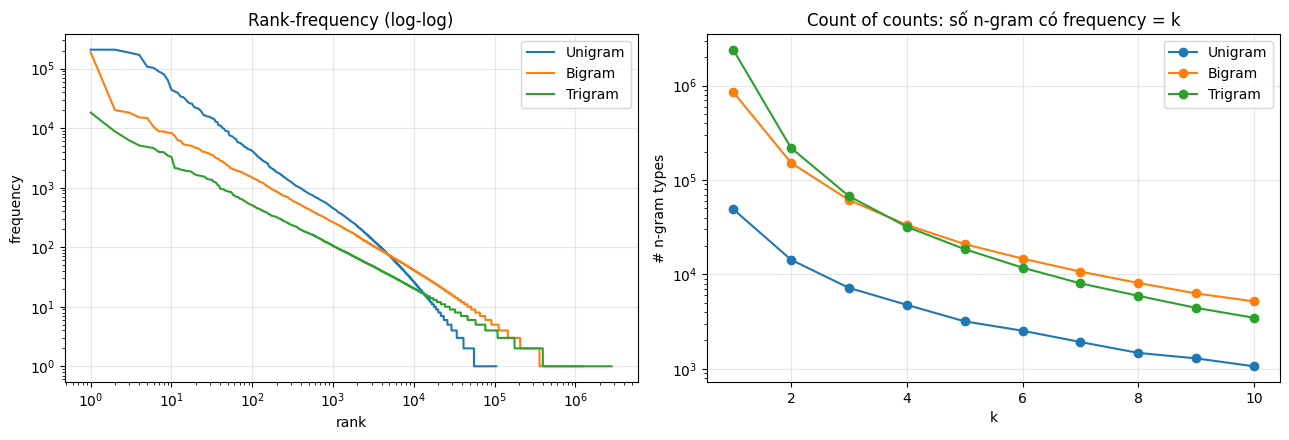

Unigram top-10: [('</s>', 208519), ('.', 208330), ('the', 186025), (',', 170105), ('and', 107895), ('to', 103090), ('of', 89425), ('a', 81298), ('in', 64420), ('is', 44202)]
Bigram top-10: [('. </s>', 188157), ('of the', 20126), ('<s> the', 18268), ('in the', 15176), (', and', 14822), ('! </s>', 10572), ('to the', 8857), ('<s> i', 8796), ('? </s>', 8374), (', the', 8335)]
Trigram top-10: [('<s> <s> the', 18268), ('<s> <s> i', 8796), ('<s> <s> this', 6239), ('<s> <s> we', 5125), ('<s> <s> it', 4855), ('<s> <s> in', 4634), ('<s> <s> if', 3991), (') . </s>', 3961), ('<s> <s> you', 3464), ('<s> <s> a', 3298)]


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, c in zip(["Unigram", "Bigram", "Trigram"], ngram_counts.values()):
    freqs = np.sort(np.fromiter(c.values(), dtype=np.int64))[::-1]
    axes[0].loglog(np.arange(1, len(freqs) + 1), freqs, label=name)
    coc = Counter(c.values())
    axes[1].plot(range(1, 11), [coc[k] for k in range(1, 11)], marker="o", label=name)
axes[0].set(title="Rank-frequency (log-log)", xlabel="rank", ylabel="frequency")
axes[1].set(title="Count of counts: số n-gram có frequency = k", xlabel="k", ylabel="# n-gram types", yscale="log")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

for name, c in zip(["Unigram", "Bigram", "Trigram"], ngram_counts.values()):
    print(name, "top-10:", [(" ".join(g), f) for g, f in c.most_common(10)])

**Nhận xét.**
- Vocabulary (≈ 105K word types) không phụ thuộc n; số n-gram types tăng 105K → 1.22M → 2.80M.
- Tỉ lệ n-gram chỉ xuất hiện 1 lần tăng 47% → 70% → 86%: n càng lớn dữ liệu càng thưa.
- Rank-frequency gần tuyến tính trên log-log (Zipf); đường trigram phẳng và dài nhất.

## 2. Kiểm tra implementation trên corpus của bài tính tay (Bài 1-4, mục 9, 11, 18)

In [4]:
toy = [s.split() for s in ["the cat eats fish", "the cat likes fish", "the dog eats meat"]]
uni = L.train_unigram(toy, pad=False)
big = L.train_bigram(toy, pad=False)
print("Bài 1:", {w: round(uni[w], 4) for w in ["the", "cat", "fish", "dog"]}, "| sum P(w) =", sum(uni.values()))
print("Bài 2:", {k: round(big[(h,)][w], 4) for k, h, w in [("P(cat|the)", "the", "cat"), ("P(dog|the)", "the", "dog"),
                                                          ("P(eats|cat)", "cat", "eats"), ("P(likes|cat)", "cat", "likes")]})
p = lambda s: uni[s[0]] * math.prod(big[(a,)].get(b, 0) for a, b in zip(s, s[1:]))
print("Bài 3: P(the cat eats fish) =", p("the cat eats fish".split()))
print("Bài 4: P(S1) =", p("the cat eats fish".split()), " P(S2) =", p("the dog eats fish".split()))

toy2 = [s.split() for s in ["I like NLP", "I like AI", "I study NLP"]]
print("Mục 9: C(study AI) =", L.count_ngrams(toy2, 2, pad=False)[("study", "AI")],
      "| P_MLE(AI|study) =", L.train_bigram(toy2, pad=False)[("study",)].get("AI", 0.0))
print("Mục 11:", (0 + 1) / (10 + 5), (3 + 1) / (10 + 5))
for p2 in (0.25, 0.1):
    pw = 0.5 * p2 * 0.5
    print(f"Mục 18: P(w2|w1)={p2}: P(W)={pw}, PP={pw ** (-1/3):.4f}")

Bài 1: {'the': 0.25, 'cat': 0.1667, 'fish': 0.1667, 'dog': 0.0833} | sum P(w) = 1.0
Bài 2: {'P(cat|the)': 0.6667, 'P(dog|the)': 0.3333, 'P(eats|cat)': 0.5, 'P(likes|cat)': 0.5}
Bài 3: P(the cat eats fish) = 0.041666666666666664
Bài 4: P(S1) = 0.041666666666666664  P(S2) = 0.041666666666666664
Mục 9: C(study AI) = 0 | P_MLE(AI|study) = 0.0
Mục 11: 0.06666666666666667 0.26666666666666666
Mục 18: P(w2|w1)=0.25: P(W)=0.0625, PP=2.5198
Mục 18: P(w2|w1)=0.1: P(W)=0.025, PP=3.4200


In [5]:
# Tổng xác suất có điều kiện = 1 trên model thật (MLE và Laplace)
models = {}
for n in (1, 2, 3):
    models[(n, "mle")] = L.NGramLanguageModel(n, "mle", MIN_COUNT).fit(train)
    models[(n, "laplace")] = models[(n, "mle")].with_smoothing("laplace")
vocab = models[(1, "mle")].vocab
for (n, sm), m in models.items():
    ctx = ["of", "the"][-(n - 1):] if n > 1 else []
    print(f"{m.name:16s} sum_w P(w | {' '.join(ctx) or '-'}) = {sum(m.probability(ctx, w) for w in vocab):.6f}")

Unigram MLE      sum_w P(w | -) = 1.000000
Unigram Laplace  sum_w P(w | -) = 1.000000
Bigram MLE       sum_w P(w | the) = 1.000000
Bigram Laplace   sum_w P(w | the) = 1.000000
Trigram MLE      sum_w P(w | of the) = 1.000000


Trigram Laplace  sum_w P(w | of the) = 1.000000


## 3. Log probability

In [6]:
m = models[(2, "laplace")]
long_sentence = [w for s in test[:60] for w in s]   # ghép nhiều câu test thành 1 sequence dài
probs = m.token_probabilities(long_sentence)
print("số token:", len(probs))
print("tích trực tiếp  prod P =", math.prod(probs))
print("tổng log        sum log P =", sum(math.log(p) for p in probs))
print("sentence_log_probability =", m.sentence_log_probability(long_sentence))
print("float64 nhỏ nhất (subnormal) ~", np.nextafter(0, 1))

số token: 1024
tích trực tiếp  prod P = 0.0
tổng log        sum log P = -8805.61756080971
sentence_log_probability = -8805.617560809693
float64 nhỏ nhất (subnormal) ~ 5e-324


**Vì sao log probability tránh underflow?** Tích của ~1000 thừa số < 1 nhỏ hơn số float64 dương nhỏ nhất (~5e-324) nên bị làm tròn thành `0.0`, dù xác suất thật là e^−8806 ≈ 10^−3824 ≠ 0. Log biến tích thành tổng: log P(S) = Σ log P(w_t|context) = −8806, biểu diễn được chính xác.

## 4. Experiment 2 - MLE vs Laplace smoothing

In [7]:
splits = {"train": train, "valid": valid, "test": test}
evals = {}
for key, m in models.items():
    evals[key] = {sp: m.evaluate(data) for sp, data in splits.items()}

rows = []
for n in (2, 3):
    for sm in ("mle", "laplace"):
        e = evals[(n, sm)]
        rows.append({"Model": models[(n, sm)].name,
                     "Train PPL": e["train"]["perplexity"], "Valid PPL": e["valid"]["perplexity"],
                     "Test PPL": e["test"]["perplexity"],
                     "% token P=0 (valid)": 100 * e["valid"]["zero_prob_rate"],
                     "% token P=0 (test)": 100 * e["test"]["zero_prob_rate"]})
exp2 = pd.DataFrame(rows)
exp2.round(2)

,Model,Train PPL,Valid PPL,Test PPL,% token P=0 (valid),% token P=0 (test)
0,Bigram MLE,104.31,inf,inf,20.43,19.85
1,Bigram Laplace,1943.00,2241.56,2190.57,0.00,0.00
2,Trigram MLE,9.68,inf,inf,58.61,58.21
3,Trigram Laplace,10248.04,16200.30,16247.15,0.00,0.00


In [8]:
# Laplace lấy bao nhiêu xác suất từ các n-gram đã thấy? Ví dụ context phổ biến
for n, ctx in [(2, ["the"]), (3, ["one", "of"]), (3, ["the", "cat"])]:
    mle, lap = models[(n, "mle")], models[(n, "laplace")]
    h = mle._context(ctx)
    seen = mle.followers.get(h, {})
    top = max(seen, key=seen.get)
    print(f"{n}-gram, context '{' '.join(ctx)}': C(h)={mle.context_counts[h]}, #seen followers={len(seen)}, V={mle.V}")
    print(f"   top word '{top}': MLE={mle.probability(ctx, top):.4f}  Laplace={lap.probability(ctx, top):.4f}")
    print(f"   tổng mass cho các từ đã thấy: MLE=1.0000  Laplace={sum(lap.probability(ctx, w) for w in seen):.4f}")

2-gram, context 'the': C(h)=147255, #seen followers=17259, V=48963
   top word '<unk>': MLE=0.0180  Laplace=0.0135
   tổng mass cho các từ đã thấy: MLE=1.0000  Laplace=0.8384
3-gram, context 'one of': C(h)=2108, #seen followers=160, V=48963
   top word 'the': MLE=0.5991  Laplace=0.0247
   tổng mass cho các từ đã thấy: MLE=1.0000  Laplace=0.0444
3-gram, context 'the cat': C(h)=17, #seen followers=12, V=48963
   top word 'queen': MLE=0.2941  Laplace=0.0001
   tổng mass cho các từ đã thấy: MLE=1.0000  Laplace=0.0006


**Tại sao kết quả như vậy?**
- **MLE trên train thấp** (bigram 104.3, trigram 9.7): MLE cực đại likelihood trên chính train; 86% trigram chỉ xuất hiện 1 lần nên trigram gần như thuộc lòng train.
- **MLE trên valid/test = ∞**: 20% (bigram) và 58% (trigram) token thuộc n-gram chưa gặp → P = 0 → PPL = ∞.
- **Laplace** cho PPL hữu hạn nhưng rất cao (test: bigram 2 191, trigram 16 247, tệ hơn unigram 926) vì V = 48 963 lớn so với C(h): các từ đã thấy chỉ còn giữ 84% mass với context `the` (C = 147 255), 4.4% với `one of` (C = 2 108), 0.06% với `the cat` (C = 17). Context trigram có count nhỏ hơn nên bị san phẳng nặng hơn.
- Train PPL của Laplace cũng tăng (104.3 → 1 943) vì mass bị lấy khỏi chính các n-gram trong train.

## 5. Experiment 3 - Perplexity: Unigram / Bigram / Trigram

In [9]:
rows = []
for sm in ("mle", "laplace"):
    for n in (1, 2, 3):
        e = evals[(n, sm)]
        rows.append({"Model": models[(n, sm)].name, "Train": e["train"]["perplexity"],
                     "Validation": e["valid"]["perplexity"], "Test": e["test"]["perplexity"]})
exp3 = pd.DataFrame(rows)
exp3.round(2)

,Model,Train,Validation,Test
0,Unigram MLE,1078.24,941.57,922.30
1,Bigram MLE,104.31,inf,inf
2,Trigram MLE,9.68,inf,inf
3,Unigram Laplace,1079.59,944.82,925.72
4,Bigram Laplace,1943.00,2241.56,2190.57
5,Trigram Laplace,10248.04,16200.30,16247.15


In [10]:
# Ảnh hưởng của corpus size: train trên 25% / 50% / 100% train docs, cố định vocabulary (của full train)
size_rows = []
for frac in (0.25, 0.5, 1.0):
    sub = L.flatten(train_docs[: int(frac * len(train_docs))])
    for n in (1, 2, 3):
        m = L.NGramLanguageModel(n, "mle").fit(sub, vocabulary=vocab)
        lap = m.with_smoothing("laplace")
        size_rows.append({"train docs": int(frac * len(train_docs)), "n": n, "train tokens": m.num_tokens,
                          "Train PPL (MLE)": m.perplexity(sub),
                          "Test PPL (Laplace)": lap.perplexity(test),
                          "% test n-gram tokens unseen": 100 * m.unseen_ngram_stats(test)["unseen_token_rate"]})
    del m, lap
corpus_size = pd.DataFrame(size_rows).sort_values(["n", "train docs"])
corpus_size.round(2)

,train docs,n,train tokens,Train PPL (MLE),Test PPL (Laplace),% test n-gram tokens unseen
0,2000,1,937832,1020.71,960.60,1.09
3,4000,1,1771458,1051.25,939.93,0.36
6,8000,1,3498422,1078.24,925.72,0.00
1,2000,2,937832,69.41,4346.15,30.25
4,4000,2,1771458,85.87,3109.97,24.93
7,8000,2,3498422,104.31,2190.57,19.85
2,2000,3,937832,5.99,23836.22,69.13
5,4000,3,1771458,7.55,20071.88,63.97
8,8000,3,3498422,9.68,16247.15,58.21


**Giải thích.**
- **Training PPL giảm** 1 078 → 104 → 9.7 (MLE): context dài hơn cho phân phối có điều kiện nhọn hơn, context bậc cao chỉ gặp vài lần nên mô hình nhớ lại được từ tiếp theo.
- **Valid/test không cải thiện**: MLE = ∞ với bigram/trigram; Laplace tăng 926 → 2 191 → 16 247 vì tỉ lệ token rơi vào n-gram chưa thấy tăng 0% → 20% → 58% (mục 6).
- **Overfitting**: khoảng cách train-test tăng theo n (trigram: train 9.7, test ∞ / 16 247). Unigram không overfit (test 922 ≤ train 1 078).
- **Corpus size** (cố định vocabulary): 2K → 8K docs làm tỉ lệ unseen trigram giảm 69% → 58%, test PPL giảm (bigram 4 346 → 2 191, trigram 23 836 → 16 247), train PPL tăng (trigram 5.99 → 9.68): khoảng cách train/test thu hẹp.

## 6. Context length: context dài hơn có luôn tốt hơn?

In [11]:
rows = []
for n in (1, 2, 3):
    mle, lap = models[(n, "mle")], models[(n, "laplace")]
    us_val, us_test = mle.unseen_ngram_stats(valid), mle.unseen_ngram_stats(test)
    rows.append({"Model": ["", "Unigram", "Bigram", "Trigram"][n],
                 "# n-gram types (train)": mle.num_ngrams,
                 "Train PPL (MLE)": evals[(n, "mle")]["train"]["perplexity"],
                 "Valid PPL (Laplace)": evals[(n, "laplace")]["valid"]["perplexity"],
                 "Test PPL (Laplace)": evals[(n, "laplace")]["test"]["perplexity"],
                 "# unseen n-gram types (test)": us_test["unseen_types"],
                 "% unseen types (test)": 100 * us_test["unseen_type_rate"],
                 "% unseen tokens (valid)": 100 * us_val["unseen_token_rate"],
                 "% unseen tokens (test)": 100 * us_test["unseen_token_rate"]})
context_len = pd.DataFrame(rows)
context_len.round(2)

,Model,# n-gram types (train),Train PPL (MLE),Valid PPL (Laplace),Test PPL (Laplace),# unseen n-gram types (test),% unseen types (test),% unseen tokens (valid),% unseen tokens (test)
0,Unigram,48963,1078.24,944.82,925.72,0,0.00,0.00,0.00
1,Bigram,955967,104.31,2241.56,2190.57,77891,42.18,20.43,19.85
2,Trigram,2236873,9.68,16200.30,16247.15,242759,72.26,58.61,58.21


**Context dài hơn có luôn tốt hơn? - Không.**
Chỉ tốt hơn trên **train** (9.7 < 104 < 1 078). Trên valid/test, cùng Laplace: unigram 926 < bigram 2 191 < trigram 16 247. Số n-gram types tăng 49K → 956K → 2.24M, 72% trigram types của test (58% token) không có trong train. Với ~3.5M token train, sparsity lấn át thông tin thêm từ context. Top-1 accuracy (mục 9): bigram 17.3% > trigram 15.8%.

## 7. Application - Next-word prediction

In [12]:
def actual_next(ctx, datasets=(("test", test), ("valid", valid))):
    k = len(ctx)
    for name, data in datasets:
        for s in data:
            for i in range(len(s) - k):
                if s[i:i + k] == ctx:
                    return s[i + k], name
    return None, None

CONTEXTS = ["the cat", "natural language", "machine learning", "united states", "i would like",
            "thank you for", "in order", "at the same"]
nw_rows = []
for c in CONTEXTS:
    ctx = c.split()
    actual, src = actual_next(ctx)
    for n in (2, 3):
        m = models[(n, "mle")]
        top = m.next_word_distribution(ctx, 3)
        nw_rows.append({"Context": c, "Model": m.name, "C(h)": m.context_counts.get(m._context(ctx), 0),
                        "Prediction (top-3)": ", ".join(f"{w} {p:.3f}" for w, p in top),
                        "Actual next word": f"{actual} ({src})",
                        "P(actual)": m.probability(ctx, actual),
                        "Top-1 đúng": bool(top) and top[0][0] == actual})
next_word = pd.DataFrame(nw_rows)
next_word

,Context,Model,C(h),Prediction (top-3),Actual next word,P(actual),Top-1 đúng
0,the cat,Bigram MLE,172,"house 0.116, , 0.087, to 0.064",had (test),0.000000,False
1,the cat,Trigram MLE,17,"queen 0.294, house 0.118, "" 0.059",had (test),0.000000,False
2,natural language,Bigram MLE,427,", 0.141, . 0.124, and 0.063",processing (test),0.000000,False
3,natural language,Trigram MLE,2,. 1.000,processing (test),0.000000,False
4,machine learning,Bigram MLE,641,". 0.084, about 0.059, and 0.059",", (test)",0.051482,False
5,machine learning,Trigram MLE,39,"and 0.154, - 0.103, . 0.103",", (test)",0.025641,False
6,united states,Bigram MLE,664,", 0.166, . 0.163, and 0.065",against (test),0.000000,False
7,united states,Trigram MLE,359,", 0.203, . 0.173, and 0.070",against (test),0.000000,False
8,i would like,Bigram MLE,4449,"to 0.126, a 0.094, the 0.088",to (test),0.126321,True
9,i would like,Trigram MLE,332,"to 0.819, . 0.024, your 0.024",to (test),0.819277,True


In [13]:
print("Input: the cat  (Trigram MLE)")
for i, (w, p) in enumerate(models[(3, "mle")].next_word_distribution("the cat".split(), 5), 1):
    print(f"{i}. {w} {p:.2f}")

Input: the cat  (Trigram MLE)
1. queen 0.29
2. house 0.12
3. " 0.06
4. , 0.06
5. . 0.06


**Nhận xét.** Top-1 đúng 3/8 context (`i would like → to`, `in order → to`, `at the same → time`), đều là collocation cố định; trigram tự tin hơn khi đúng (`in order → to`: 0.895 vs 0.463). Sai khi context hiếm hoặc lệch domain: `natural language` (C = 2), `the cat` (C = 17), `united states → against` (phụ thuộc ngữ cảnh xa hơn 2 từ).

## 8. Application - Sentence ranking

In [14]:
def rank(context, candidates, n):
    rows = []
    for label, cand in candidates.items():
        toks = L.tokenize(cand)
        r = {"Candidate": f"{label}. {cand}"}
        for sm in ("mle", "laplace"):
            lp = models[(n, sm)].continuation_log_probability(L.tokenize(context), toks)
            r[f"log P ({sm})"] = lp
            r[f"log P / token ({sm})"] = lp / len(toks)
        rows.append(r)
    df = pd.DataFrame(rows).sort_values("log P / token (laplace)", ascending=False)
    df.insert(0, "Rank", range(1, len(df) + 1))
    return df

cands = {"A": "is useful for NLP", "B": "banana computer quickly", "C": "studies language models"}
print("Context: machine learning")
for n in (2, 3):
    print(f"--- {n}-gram"); display(rank("machine learning", cands, n).round(3))

Context: machine learning
--- 2-gram


,Rank,Candidate,log P (mle),log P / token (mle),log P (laplace),log P / token (laplace)
0,1,A. is useful for NLP,-18.477,-4.619,-29.563,-7.391
1,2,B. banana computer quickly,-inf,-inf,-32.421,-10.807
2,3,C. studies language models,-inf,-inf,-32.425,-10.808


--- 3-gram


,Rank,Candidate,log P (mle),log P / token (mle),log P (laplace),log P / token (laplace)
0,1,A. is useful for NLP,-inf,-inf,-40.800,-10.200
1,2,B. banana computer quickly,-inf,-inf,-32.397,-10.799
2,3,C. studies language models,-inf,-inf,-32.397,-10.799


In [15]:
cands2 = {"A": "to take this opportunity", "B": "opportunity this take to", "C": "to eat the opportunity"}
print("Context: i would like"); display(rank("i would like", cands2, 3).round(3))

Context: i would like


,Rank,Candidate,log P (mle),log P / token (mle),log P (laplace),log P / token (laplace)
0,1,A. to take this opportunity,-11.315,-2.829,-32.138,-8.035
2,2,C. to eat the opportunity,-inf,-inf,-34.611,-8.653
1,3,B. opportunity this take to,-inf,-inf,-43.202,-10.801


**Nhận xét.**
- Bigram Laplace: A > B ≈ C. MLE cho B, C = −∞ nên không phân biệt được câu vô nghĩa (B) với câu hợp lý nhưng chưa gặp (C).
- Trigram MLE: cả 3 đều −∞ → không xếp hạng được.
- Trigram Laplace: theo tổng log P, A (4 token) xếp cuối chỉ vì dài hơn; theo log P / token A đứng đầu → cần chuẩn hóa độ dài (Bài 3).
- Ví dụ 2: LM nắm được thứ tự từ, A > C > B.

## 9. Error analysis
Top-1/top-5 accuracy trên test cho biết mức đúng chung; 4 case (2 đúng, 2 sai) lấy từ 8 context ở mục 7, expected = từ đứng sau context lần đầu tiên nó xuất hiện trong test.

In [16]:
rng = random.Random(0)
test_positions = []
for s in rng.sample(test, 3000):
    toks = L.pad_sentence(s, 3)
    for i in range(2, len(toks)):
        test_positions.append((toks[:i], toks[i]))

acc_rows, cases = [], {}
for n in (1, 2, 3):
    m = models[(n, "mle")]
    hit1 = hit5 = 0
    cache = {}  # top-5 theo context (unigram: 1 context duy nhất)
    for hist, gold in test_positions:
        h = m._context(hist)
        if h not in cache:
            cache[h] = m.next_word_distribution(hist, 5)
        top = cache[h]
        gold_m = gold if gold in m.vocab else L.UNK
        hit1 += bool(top) and top[0][0] == gold_m
        hit5 += gold_m in [w for w, _ in top]
    acc_rows.append({"Model": m.name, "positions": len(test_positions),
                     "top-1 acc": hit1 / len(test_positions), "top-5 acc": hit5 / len(test_positions)})
accuracy = pd.DataFrame(acc_rows)
accuracy.round(4)

,Model,positions,top-1 acc,top-5 acc
0,Unigram MLE,65262,0.0460,0.1956
1,Bigram MLE,65262,0.1725,0.3395
2,Trigram MLE,65262,0.1579,0.2582


In [17]:
ERROR_CASES = [['in order', 'to'], ['at the same', 'time'], ['natural language', 'processing'], ['the cat', 'had']]

m3, m2 = models[(3, "mle")], models[(2, "mle")]
def show(context, expected):
    hist = [L.BOS, L.BOS] + context.split()
    top = m3.next_word_distribution(hist, 3)
    h = m3._context(hist)
    print(f"Context: {context!r}   (trigram context = {h}, C(h) = {m3.context_counts.get(h, 0)})")
    print(f"  Model prediction (trigram): {[(w, round(p, 3)) for w, p in top] or 'NONE (unseen context)'}")
    print(f"  Bigram prediction         : {[(w, round(p, 3)) for w, p in m2.next_word_distribution(hist, 3)]}")
    print(f"  Expected: {expected!r}  P_tri = {m3.probability(hist, expected):.4f}  "
          f"P_bi = {m2.probability(hist, expected):.4f}  in vocab: {expected in m3.vocab}")

for context, expected in ERROR_CASES:
    show(context, expected); print()

Context: 'in order'   (trigram context = ('in', 'order'), C(h) = 563)
  Model prediction (trigram): [('to', 0.895), ('for', 0.043), ('that', 0.014)]
  Bigram prediction         : [('to', 0.463), ('.', 0.079), ('for', 0.035)]
  Expected: 'to'  P_tri = 0.8952  P_bi = 0.4632  in vocab: True

Context: 'at the same'   (trigram context = ('the', 'same'), C(h) = 1365)
  Model prediction (trigram): [('time', 0.138), ('.', 0.053), ('way', 0.04)]
  Bigram prediction         : [('time', 0.124), ('.', 0.051), ('way', 0.037)]
  Expected: 'time'  P_tri = 0.1377  P_bi = 0.1237  in vocab: True

Context: 'natural language'   (trigram context = ('natural', 'language'), C(h) = 2)
  Model prediction (trigram): [('.', 1.0)]
  Bigram prediction         : [(',', 0.141), ('.', 0.124), ('and', 0.063)]
  Expected: 'processing'  P_tri = 0.0000  P_bi = 0.0000  in vocab: True

Context: 'the cat'   (trigram context = ('the', 'cat'), C(h) = 17)
  Model prediction (trigram): [('queen', 0.294), ('house', 0.118), ('"',

In [18]:
# Kiểm chứng nguyên nhân: các context này xuất hiện ở đâu trong train
def occurrences(phrase, width=6):
    p = phrase.split(); k = len(p); hits = []
    for d_id, d in enumerate(train_docs):
        for s in d:
            for i in range(len(s) - k + 1):
                if s[i:i + k] == p:
                    hits.append((d_id, " ".join(s[max(0, i - width):i + k + width])))
    return hits

for phrase in ["natural language", "the cat queen", "the cat"]:
    hits = occurrences(phrase)
    print(f"{phrase!r}: {len(hits)} lần, trong {len({d for d, _ in hits})} document")
    if len(hits) <= 5:
        for d, snip in hits: print(f"   doc {d}: ... {snip} ...")

after = Counter(s[i + 3] for s in train for i in range(len(s) - 3) if s[i:i + 3] == ["at", "the", "same"])
print(f"'at the same' + w: C = {sum(after.values())}, P(time | at the same) = {after['time'] / sum(after.values()):.3f}, top-3 = {after.most_common(3)}")


'natural language': 2 lần, trong 1 document
   doc 1915: ... truth - value gaps in natural language . ...
   doc 1915: ... " truth - value gaps in natural language . " ( 1980 ) . ...


'the cat queen': 5 lần, trong 1 document
   doc 7878: ... have been examining the history of the cat queen , a tabby cat who ruled ...
   doc 7878: ... the cat queen has been thought to be a ...
   doc 7878: ... benefit from the robust education system the cat queen had supposedly implemented during her years ...
   doc 7878: ... the island of boomshakalaka back to the cat queen . ...
   doc 7878: ... while the cat queen may have either been a noble ...


'the cat': 17 lần, trong 7 document


'at the same' + w: C = 179, P(time | at the same) = 0.899, top-3 = [('time', 161), ('level', 2), ('saas', 1)]


Phân tích chi tiết 2 trường hợp đúng / 2 trường hợp sai ở trên nằm trong `error_analysis.md`.

## 10. Lưu kết quả → `results.csv`

In [19]:
rows = []
for (n, sm), e in evals.items():
    for sp in ("train", "valid", "test"):
        rows.append({"experiment": "perplexity", "model": models[(n, sm)].name, "split": sp,
                     "perplexity": e[sp]["perplexity"], "zero_prob_rate": e[sp]["zero_prob_rate"]})
for r in size_rows:
    rows.append({"experiment": "corpus_size", "model": f"{r['n']}-gram", "split": f"train_docs={r['train docs']}",
                 "perplexity": r["Test PPL (Laplace)"], "train_perplexity": r["Train PPL (MLE)"],
                 "unseen_rate": r["% test n-gram tokens unseen"] / 100})
for r in nw_rows:
    rows.append({"experiment": "next_word", "model": r["Model"], "split": "test", "context": r["Context"],
                 "prediction": r["Prediction (top-3)"], "actual": r["Actual next word"],
                 "probability": r["P(actual)"], "correct": r["Top-1 đúng"]})
for r in acc_rows:
    rows.append({"experiment": "next_word_accuracy", "model": r["Model"], "split": "test",
                 "top1_acc": r["top-1 acc"], "top5_acc": r["top-5 acc"]})
results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
print(results.shape, f"total time {time.time()-t0:.0f}s")
for name, g in results.groupby("experiment", sort=False):
    print(f"--- {name}"); display(g.dropna(axis=1, how="all"))

(46, 14) total time 147s
--- perplexity


,experiment,model,split,perplexity,zero_prob_rate
0,perplexity,Unigram MLE,train,1.078243e+03,0.000000
1,perplexity,Unigram MLE,valid,9.415745e+02,0.000000
2,perplexity,Unigram MLE,test,9.222979e+02,0.000000
3,perplexity,Unigram Laplace,train,1.079592e+03,0.000000
4,perplexity,Unigram Laplace,valid,9.448205e+02,0.000000
5,perplexity,Unigram Laplace,test,9.257205e+02,0.000000
6,perplexity,Bigram MLE,train,1.043124e+02,0.000000
7,perplexity,Bigram MLE,valid,inf,0.204319
8,perplexity,Bigram MLE,test,inf,0.198494
9,perplexity,Bigram Laplace,train,1.943002e+03,0.000000


--- corpus_size


,experiment,model,split,perplexity,train_perplexity,unseen_rate
18,corpus_size,1-gram,train_docs=2000,960.603608,1020.713960,0.010909
19,corpus_size,2-gram,train_docs=2000,4346.154869,69.410627,0.302482
20,corpus_size,3-gram,train_docs=2000,23836.215420,5.987064,0.691308
21,corpus_size,1-gram,train_docs=4000,939.932538,1051.252732,0.003589
22,corpus_size,2-gram,train_docs=4000,3109.969303,85.872182,0.249349
23,corpus_size,3-gram,train_docs=4000,20071.879185,7.554942,0.639653
24,corpus_size,1-gram,train_docs=8000,925.720458,1078.242626,0.000000
25,corpus_size,2-gram,train_docs=8000,2190.568020,104.312377,0.198494
26,corpus_size,3-gram,train_docs=8000,16247.147605,9.681476,0.582130


--- next_word


,experiment,model,split,context,prediction,actual,probability,correct
27,next_word,Bigram MLE,test,the cat,"house 0.116, , 0.087, to 0.064",had (test),0.000000,False
28,next_word,Trigram MLE,test,the cat,"queen 0.294, house 0.118, "" 0.059",had (test),0.000000,False
29,next_word,Bigram MLE,test,natural language,", 0.141, . 0.124, and 0.063",processing (test),0.000000,False
30,next_word,Trigram MLE,test,natural language,. 1.000,processing (test),0.000000,False
31,next_word,Bigram MLE,test,machine learning,". 0.084, about 0.059, and 0.059",", (test)",0.051482,False
32,next_word,Trigram MLE,test,machine learning,"and 0.154, - 0.103, . 0.103",", (test)",0.025641,False
33,next_word,Bigram MLE,test,united states,", 0.166, . 0.163, and 0.065",against (test),0.000000,False
34,next_word,Trigram MLE,test,united states,", 0.203, . 0.173, and 0.070",against (test),0.000000,False
35,next_word,Bigram MLE,test,i would like,"to 0.126, a 0.094, the 0.088",to (test),0.126321,True
36,next_word,Trigram MLE,test,i would like,"to 0.819, . 0.024, your 0.024",to (test),0.819277,True


--- next_word_accuracy


,experiment,model,split,top1_acc,top5_acc
43,next_word_accuracy,Unigram MLE,test,0.045969,0.195581
44,next_word_accuracy,Bigram MLE,test,0.172459,0.339493
45,next_word_accuracy,Trigram MLE,test,0.157902,0.258205
